# Sesión 2 · Preprocesar con evidencia: filtrar, medir y decidir
**Unidad 2. Preprocesamiento** · Procesamiento Digital de Imágenes · Maestría en Ciencia de Datos e Información · INFOTEC · 2027-1

[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/egonzalez1989/pdi-mcdi/blob/main/sesiones/S2_Mejora_y_preprocesamiento.ipynb)

**Objetivo de la sesión.** Comparar técnicas de preprocesamiento y justificar la elección con PSNR y SSIM.

**Clase síncrona:** jueves 4 de febrero de 2027, de 11:00 a 13:00 hrs. · **Sesiones opcionales de la unidad** (12:00 a 13:00 hrs.): jueves 11 de febrero (dudas de la actividad 2A); jueves 25 de febrero (retroalimentación de 2A y defensas orales).

**Agenda (120 min)**
1. Retroalimentación general de la actividad 1A (10 min)
2. Intensidad, histograma y CLAHE (20 min)
3. Convolución y filtros contra ruido con PSNR/SSIM (30 min)
4. Fourier: espectro y ruido periódico (20 min)
5. Morfología y top-hat en un caso de documentos (20 min)
6. Transformaciones geométricas; actividad 2A (20 min)

**Cómo usar este cuaderno.** Ejecuta las celdas en orden (`Shift + Enter`). Las secciones marcadas con 🧪 son pausas para que experimentes cambiando parámetros; las marcadas con 💬 son preguntas para discutir en la sesión. Al final encontrarás la conexión con la actividad **2A**.

In [1]:
# Configuración del entorno. En Google Colab todas estas bibliotecas ya vienen instaladas.
import sys, platform
import numpy as np
import matplotlib.pyplot as plt
import cv2
import skimage
from skimage import data

plt.rcParams.update({"figure.dpi": 110, "axes.titlesize": 10, "image.cmap": "gray"})
np.random.seed(42)

def mostrar(imagenes, titulos=None, cols=None, cmap="gray", tam=3.2, ejes=False):
    """Muestra una lista de imágenes en una cuadrícula. Las imágenes a color deben estar en RGB."""
    if not isinstance(imagenes, (list, tuple)):
        imagenes = [imagenes]
    n = len(imagenes)
    cols = cols or min(n, 4)
    filas = int(np.ceil(n / cols))
    fig, axs = plt.subplots(filas, cols, figsize=(tam * cols, tam * filas), squeeze=False)
    for i, ax in enumerate(axs.flat):
        if i < n:
            im = imagenes[i]
            ax.imshow(im, cmap=None if im.ndim == 3 else cmap)
            if titulos:
                ax.set_title(titulos[i])
        if not ejes or i >= n:
            ax.axis("off")
    plt.tight_layout()
    plt.show()

print(f"Python {platform.python_version()} | NumPy {np.__version__} | OpenCV {cv2.__version__} | scikit-image {skimage.__version__}")

import pandas as pd
from skimage.metrics import peak_signal_noise_ratio as psnr, structural_similarity as ssim
from skimage.util import random_noise, img_as_ubyte

Python 3.12.15 | NumPy 2.5.4 | OpenCV 5.0.0 | scikit-image 0.26.0


## 1. Transformaciones puntuales de intensidad
Una transformación puntual aplica una función $s = T(r)$ a cada nivel de gris $r$, sin mirar a los vecinos. Las más usadas:
- **Lineal (contraste/brillo):** $s = \alpha r + \beta$
- **Negativo:** $s = 255 - r$
- **Logarítmica:** $s = c \log(1 + r)$ — expande los oscuros.
- **Gamma:** $s = 255\,(r/255)^{\gamma}$ — $\gamma<1$ aclara, $\gamma>1$ oscurece.

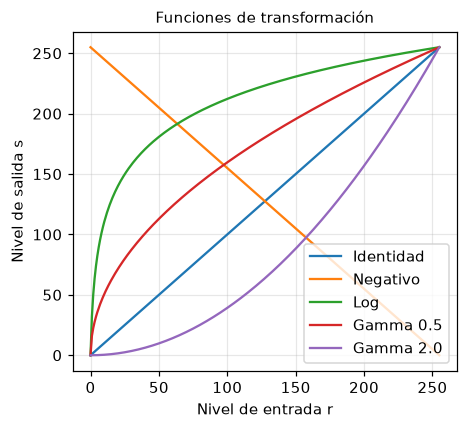

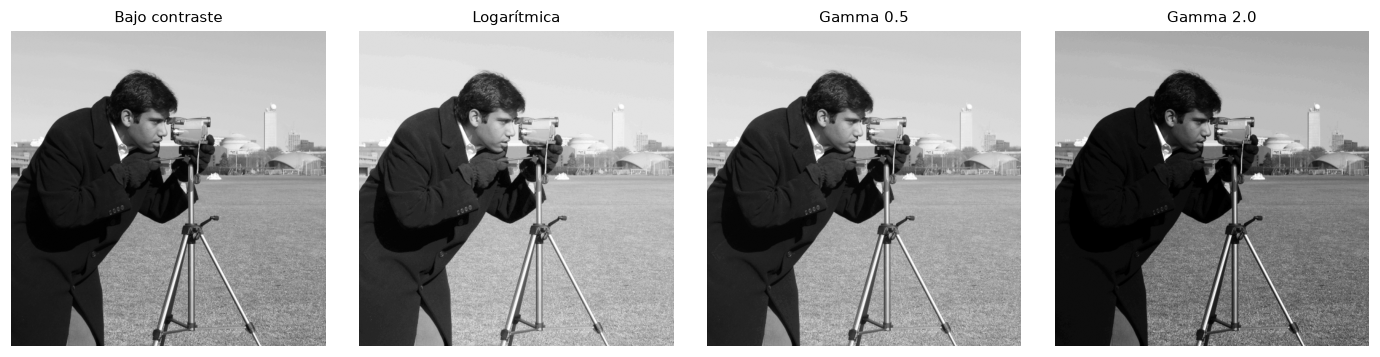

In [2]:
img = data.camera()
# Simulamos una imagen con bajo contraste, como una foto subexpuesta
bajo = (0.35 * img + 40).astype(np.uint8)

r = np.arange(256, dtype=np.float32)
curvas = {
    "Identidad": r,
    "Negativo": 255 - r,
    "Log": 255 * np.log1p(r) / np.log(256),
    "Gamma 0.5": 255 * (r / 255) ** 0.5,
    "Gamma 2.0": 255 * (r / 255) ** 2.0,
}
plt.figure(figsize=(4.5, 4))
for k, v in curvas.items():
    plt.plot(r, v, label=k)
plt.xlabel("Nivel de entrada r"); plt.ylabel("Nivel de salida s"); plt.legend(); plt.title("Funciones de transformación")
plt.grid(alpha=.3); plt.show()

aplicar = lambda im, lut: cv2.LUT(im, np.clip(lut, 0, 255).astype(np.uint8))   # tabla de consulta: rapidísimo
mostrar([bajo, aplicar(bajo, curvas["Log"]), aplicar(bajo, curvas["Gamma 0.5"]), aplicar(bajo, curvas["Gamma 2.0"])],
        ["Bajo contraste", "Logarítmica", "Gamma 0.5", "Gamma 2.0"])

## 2. Histograma, ecualización y CLAHE
El histograma cuenta cuántos píxeles hay en cada nivel. Un histograma estrecho indica bajo contraste.
- **Ecualización global:** usa la función de distribución acumulada como transformación para "aplanar" el histograma.
- **CLAHE** (*Contrast Limited Adaptive Histogram Equalization*): ecualiza por bloques y limita la amplificación del ruido. Es el estándar en imágenes médicas y de documentos.

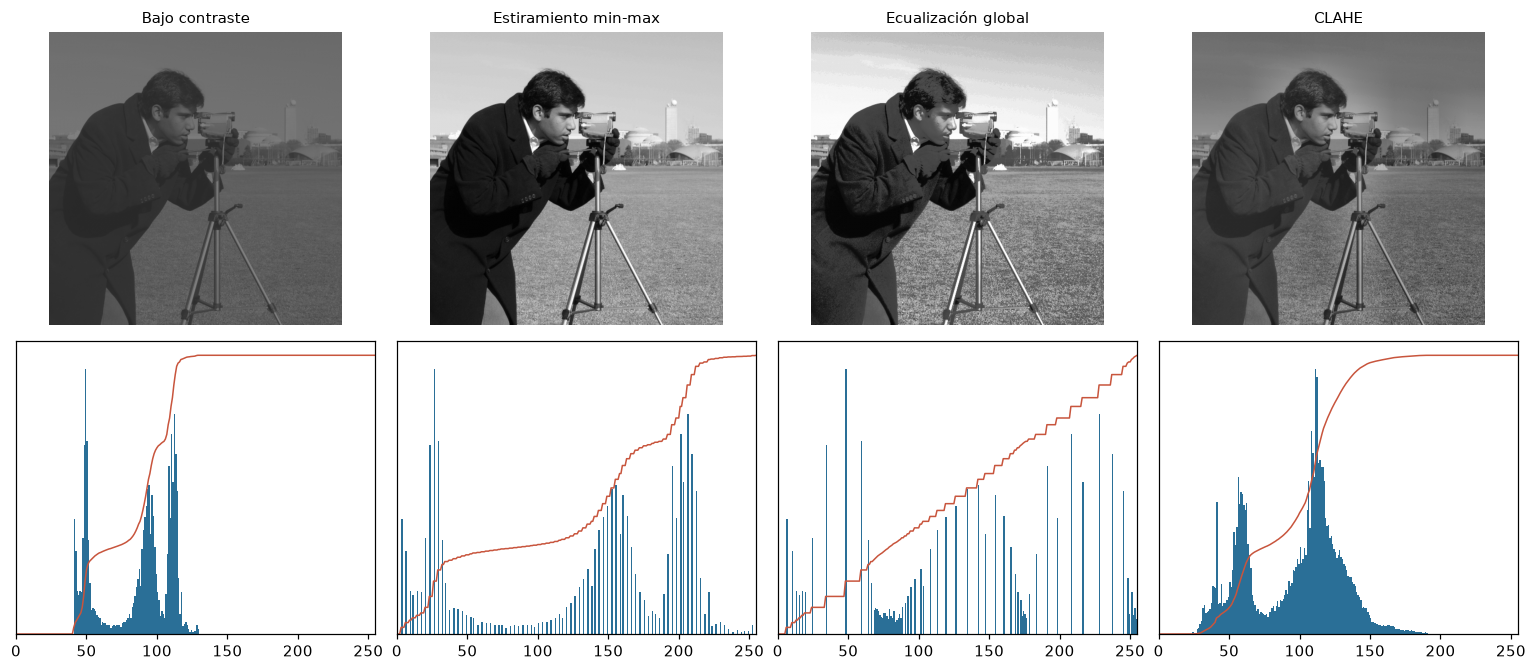

In [3]:
eq = cv2.equalizeHist(bajo)
clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8)).apply(bajo)
estirada = cv2.normalize(bajo, None, 0, 255, cv2.NORM_MINMAX)

fig, axs = plt.subplots(2, 4, figsize=(14, 6.2))
for j, (im, t) in enumerate([(bajo, "Bajo contraste"), (estirada, "Estiramiento min-max"),
                              (eq, "Ecualización global"), (clahe, "CLAHE")]):
    axs[0, j].imshow(im, cmap="gray", vmin=0, vmax=255); axs[0, j].set_title(t); axs[0, j].axis("off")
    axs[1, j].hist(im.ravel(), bins=256, range=(0, 256), color="#2a6f97")
    axs[1, j].plot(np.cumsum(np.bincount(im.ravel(), minlength=256)) / im.size * axs[1, j].get_ylim()[1], color="#c8553d", lw=1)
    axs[1, j].set_xlim(0, 255); axs[1, j].set_yticks([])
plt.tight_layout(); plt.show()

💬 **Discusión.** La ecualización global maximiza el contraste, pero ¿qué le pasa al cielo de la imagen? ¿Por qué CLAHE se ve más natural?

## 3. Convolución paso a paso
El filtrado espacial lineal es una **convolución**: cada píxel de salida es la suma ponderada de su vecindario por un **kernel** $w$:
$$g(x, y) = \sum_{s=-a}^{a}\sum_{t=-b}^{b} w(s, t)\, f(x+s, y+t)$$
Primero la implementamos "a mano" sobre una matriz pequeña para entender qué hace `cv2.filter2D`.

In [4]:
f = np.array([[10, 10, 10, 10, 10],
              [10, 50, 50, 50, 10],
              [10, 50, 200, 50, 10],
              [10, 50, 50, 50, 10],
              [10, 10, 10, 10, 10]], dtype=np.float32)
w = np.ones((3, 3), np.float32) / 9            # kernel promedio 3×3

def convolucion_manual(f, w):
    a = w.shape[0] // 2
    fp = np.pad(f, a, mode="reflect")
    g = np.zeros_like(f)
    for i in range(f.shape[0]):
        for j in range(f.shape[1]):
            g[i, j] = np.sum(fp[i:i + w.shape[0], j:j + w.shape[1]] * w)
    return g

manual = convolucion_manual(f, w)
opencv = cv2.filter2D(f, -1, w, borderType=cv2.BORDER_REFLECT_101)
print("Resultado manual:\n", manual.round(1))
print("¿Coincide con cv2.filter2D?", np.allclose(manual, opencv))

Resultado manual:
 [[27.8 27.8 36.7 27.8 27.8]
 [27.8 44.4 53.3 44.4 27.8]
 [36.7 53.3 66.7 53.3 36.7]
 [27.8 44.4 53.3 44.4 27.8]
 [27.8 27.8 36.7 27.8 27.8]]
¿Coincide con cv2.filter2D? True


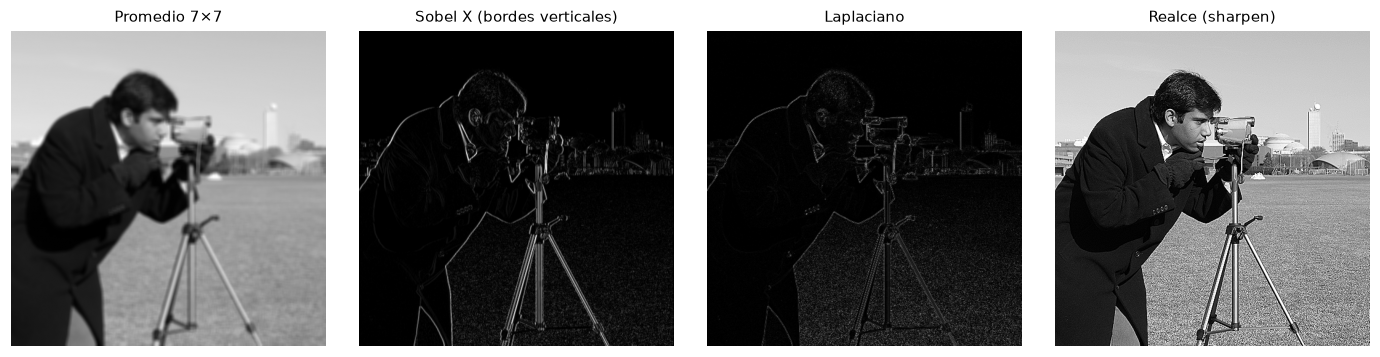

In [5]:
kernels = {
    "Promedio 7×7": np.ones((7, 7), np.float32) / 49,
    "Sobel X (bordes verticales)": np.array([[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]], np.float32),
    "Laplaciano": np.array([[0, 1, 0], [1, -4, 1], [0, 1, 0]], np.float32),
    "Realce (sharpen)": np.array([[0, -1, 0], [-1, 5, -1], [0, -1, 0]], np.float32),
}
salidas = []
for k in kernels.values():
    out = cv2.filter2D(img.astype(np.float32), -1, k)
    salidas.append(np.abs(out) if k.sum() == 0 else np.clip(out, 0, 255))
mostrar(salidas, list(kernels.keys()))

## 4. Ruido y filtros: decidir con métricas
Simulamos dos tipos de ruido frecuentes y comparamos filtros con dos métricas de referencia completa:
- **PSNR** (dB): $10\log_{10}(255^2/\mathrm{MSE})$. Mayor es mejor.
- **SSIM** ∈ [−1, 1]: compara luminancia, contraste y estructura (Wang et al., 2004). Más cercano a la percepción humana.

In [6]:
ruidos = {
    "Gaussiano σ=0.08": img_as_ubyte(random_noise(img, mode="gaussian", var=0.08**2, rng=1)),
    "Sal y pimienta 5%": img_as_ubyte(random_noise(img, mode="s&p", amount=0.05, rng=1)),
}
filtros = {
    "Promedio 5": lambda x: cv2.blur(x, (5, 5)),
    "Gaussiano 5": lambda x: cv2.GaussianBlur(x, (5, 5), 0),
    "Mediana 3": lambda x: cv2.medianBlur(x, 3),
    "Mediana 5": lambda x: cv2.medianBlur(x, 5),
    "Bilateral": lambda x: cv2.bilateralFilter(x, 9, 75, 75),
    "NL-means": lambda x: cv2.fastNlMeansDenoising(x, None, h=15),
}
filas, ejemplos = [], {}
for nr, ruidosa in ruidos.items():
    filas.append((nr, "(sin filtrar)", psnr(img, ruidosa), ssim(img, ruidosa)))
    for nf, fn in filtros.items():
        out = fn(ruidosa)
        ejemplos[(nr, nf)] = out
        filas.append((nr, nf, psnr(img, out), ssim(img, out)))
tabla = pd.DataFrame(filas, columns=["Ruido", "Filtro", "PSNR (dB)", "SSIM"]).round(3)
display(tabla.style.highlight_max(subset=["PSNR (dB)", "SSIM"], color="#cde8d4").format(precision=3))

,Ruido,Filtro,PSNR (dB),SSIM
0,Gaussiano σ=0.08,(sin filtrar),22.257,0.361
1,Gaussiano σ=0.08,Promedio 5,26.156,0.685
2,Gaussiano σ=0.08,Gaussiano 5,27.781,0.697
3,Gaussiano σ=0.08,Mediana 3,26.886,0.570
4,Gaussiano σ=0.08,Mediana 5,26.821,0.658
5,Gaussiano σ=0.08,Bilateral,27.891,0.744
6,Gaussiano σ=0.08,NL-means,28.447,0.776
7,Sal y pimienta 5%,(sin filtrar),17.746,0.356
8,Sal y pimienta 5%,Promedio 5,25.095,0.584
9,Sal y pimienta 5%,Gaussiano 5,25.670,0.570


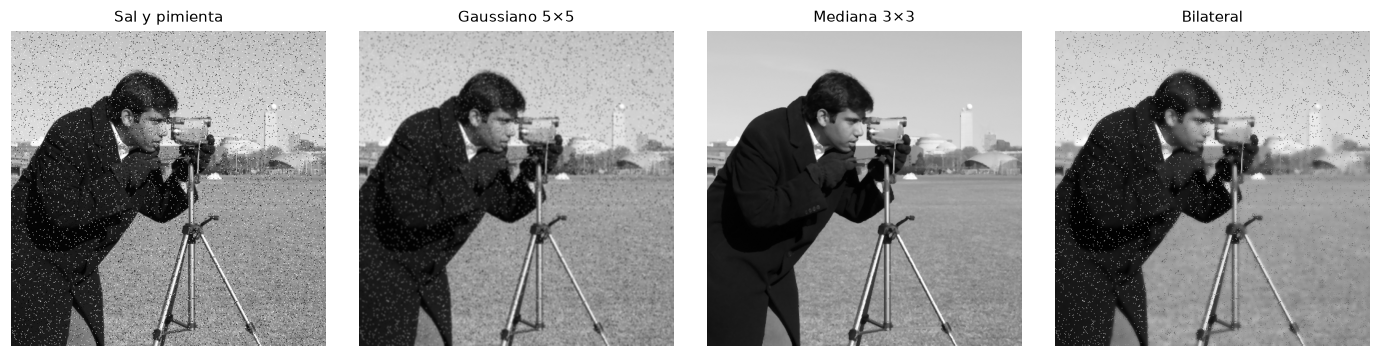

In [7]:
nr = "Sal y pimienta 5%"
mostrar([ruidos[nr], ejemplos[(nr, "Gaussiano 5")], ejemplos[(nr, "Mediana 3")], ejemplos[(nr, "Bilateral")]],
        ["Sal y pimienta", "Gaussiano 5×5", "Mediana 3×3", "Bilateral"])

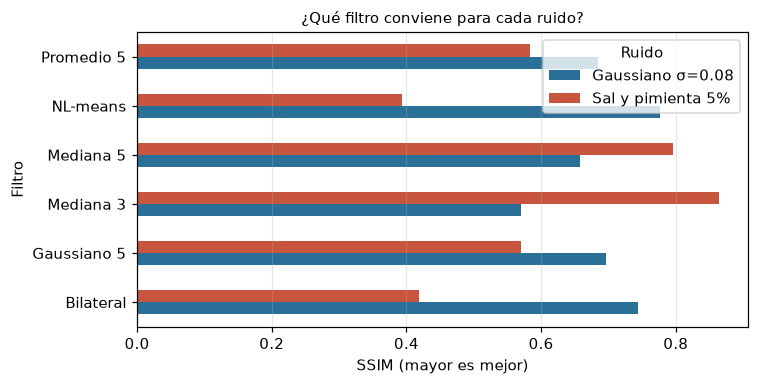

In [8]:
piv = tabla[tabla["Filtro"] != "(sin filtrar)"].pivot(index="Filtro", columns="Ruido", values="SSIM")
piv.plot.barh(figsize=(7, 3.6), color=["#2a6f97", "#c8553d"])
plt.xlabel("SSIM (mayor es mejor)"); plt.title("¿Qué filtro conviene para cada ruido?"); plt.grid(axis="x", alpha=.3)
plt.tight_layout(); plt.show()

**Conclusión basada en evidencia:** la mediana domina con ruido impulsivo (sal y pimienta) porque descarta valores extremos; con ruido gaussiano, los filtros que promedian o que preservan bordes (bilateral, NL-means) ganan. 🧪 *Cambia la intensidad del ruido y verifica si la conclusión se mantiene.*

## 5. El dominio de la frecuencia
La transformada de Fourier descompone la imagen en ondas de distintas frecuencias. Bajas frecuencias = regiones suaves; altas = bordes y ruido fino.
Un caso donde el dominio espacial no ayuda: **ruido periódico** (interferencia eléctrica, patrón de escáner). En frecuencia aparece como picos aislados que podemos eliminar con un filtro de rechazo (*notch*).

Picos de ruido detectados en: [(np.int64(224), np.int64(192)), (np.int64(288), np.int64(320))]


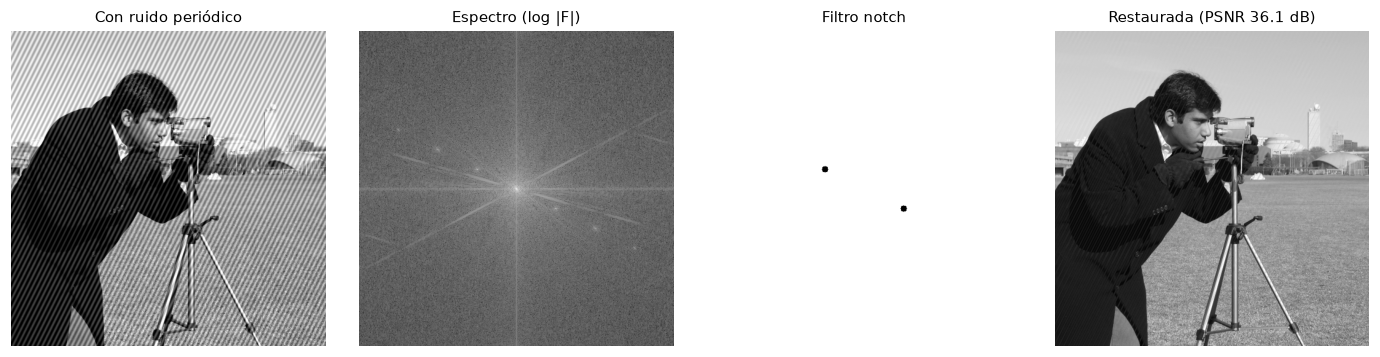

PSNR ruidosa: 19.4 dB  |  PSNR con mediana 5×5: 22.3 dB


In [9]:
filas_, cols_ = img.shape
yy, xx = np.mgrid[0:filas_, 0:cols_]
periodica = np.clip(img + 40 * np.sin(2 * np.pi * (xx / 8 + yy / 16)), 0, 255).astype(np.uint8)

F = np.fft.fftshift(np.fft.fft2(periodica))
espectro = np.log1p(np.abs(F))

# Localizamos automáticamente los picos fuera del centro y los anulamos (notch)
cy, cx = filas_ // 2, cols_ // 2
mag = np.abs(F).copy()
cv2.circle(mag, (cx, cy), 25, 0, -1)                 # ignoramos las bajas frecuencias (contenido de la escena)
py, px = np.unravel_index(np.argmax(mag), mag.shape)  # pico más fuerte fuera del centro
picos = [(py, px), (2 * cy - py, 2 * cx - px)]        # y su simétrico (el espectro de una imagen real es simétrico)
print("Picos de ruido detectados en:", picos)
mascara = np.ones(F.shape, dtype=np.float32)
for (py, px) in picos:
    cv2.circle(mascara, (int(px), int(py)), 5, 0, -1)
restaurada = np.real(np.fft.ifft2(np.fft.ifftshift(F * mascara)))
restaurada = np.clip(restaurada, 0, 255).astype(np.uint8)

mostrar([periodica, espectro, mascara, restaurada],
        ["Con ruido periódico", "Espectro (log |F|)", "Filtro notch", f"Restaurada (PSNR {psnr(img, restaurada):.1f} dB)"])
print(f"PSNR ruidosa: {psnr(img, periodica):.1f} dB  |  PSNR con mediana 5×5: {psnr(img, cv2.medianBlur(periodica, 5)):.1f} dB")

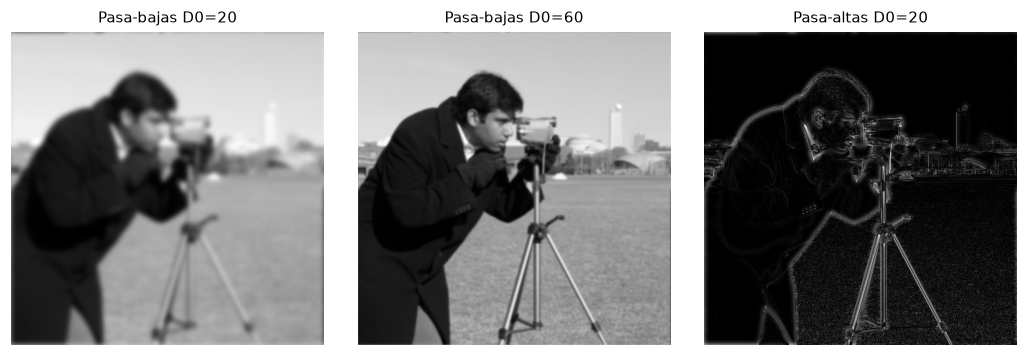

In [10]:
def filtro_gaussiano_frecuencia(im, D0, tipo="bajas"):
    F = np.fft.fftshift(np.fft.fft2(im))
    D2 = (yy - cy) ** 2 + (xx - cx) ** 2
    H = np.exp(-D2 / (2 * D0 ** 2))
    if tipo == "altas":
        H = 1 - H
    return np.real(np.fft.ifft2(np.fft.ifftshift(F * H)))

mostrar([filtro_gaussiano_frecuencia(img, 20), filtro_gaussiano_frecuencia(img, 60),
         np.abs(filtro_gaussiano_frecuencia(img, 20, "altas"))],
        ["Pasa-bajas D0=20", "Pasa-bajas D0=60", "Pasa-altas D0=20"])

## 6. Morfología matemática
Opera sobre la **forma** de los objetos en imágenes binarias (o en gris) usando un **elemento estructurante**:
| Operación | Efecto típico |
|---|---|
| Erosión | Adelgaza objetos, elimina puntos blancos |
| Dilatación | Engrosa objetos, rellena huecos pequeños |
| Apertura (erosión → dilatación) | Elimina ruido blanco sin cambiar el tamaño |
| Cierre (dilatación → erosión) | Rellena huecos y une fragmentos |
| Top-hat | Recupera detalles claros sobre fondo con iluminación desigual |

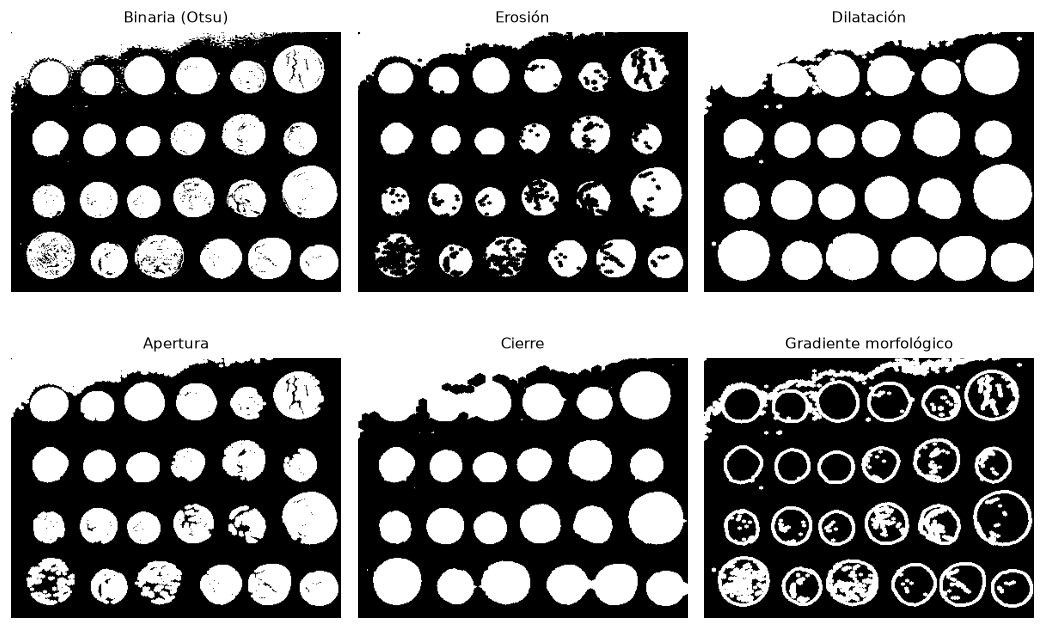

In [11]:
monedas = data.coins()
_, binaria = cv2.threshold(monedas, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
ee = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (5, 5))
ops = {
    "Binaria (Otsu)": binaria,
    "Erosión": cv2.erode(binaria, ee),
    "Dilatación": cv2.dilate(binaria, ee),
    "Apertura": cv2.morphologyEx(binaria, cv2.MORPH_OPEN, ee),
    "Cierre": cv2.morphologyEx(binaria, cv2.MORPH_CLOSE, ee, iterations=2),
    "Gradiente morfológico": cv2.morphologyEx(binaria, cv2.MORPH_GRADIENT, ee),
}
mostrar(list(ops.values()), list(ops.keys()), cols=3)

### Caso: documento con iluminación desigual
Un umbral global falla cuando la iluminación no es uniforme. El **top-hat negro** (cierre − imagen) estima y elimina el fondo.

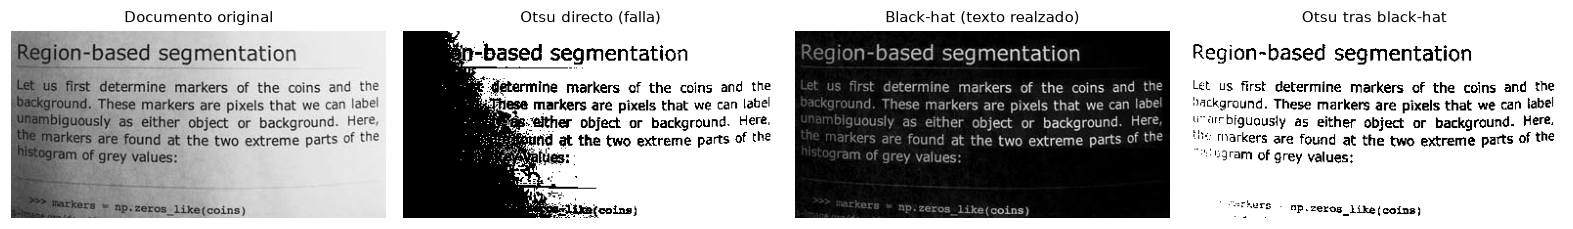

In [12]:
pagina = data.page()
_, global_ = cv2.threshold(pagina, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
ee_grande = cv2.getStructuringElement(cv2.MORPH_RECT, (15, 15))
blackhat = cv2.morphologyEx(pagina, cv2.MORPH_BLACKHAT, ee_grande)
_, tophat_bin = cv2.threshold(blackhat, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)
mostrar([pagina, global_, blackhat, tophat_bin],
        ["Documento original", "Otsu directo (falla)", "Black-hat (texto realzado)", "Otsu tras black-hat"], tam=3.6)

## 7. Transformaciones geométricas y aumento de datos
- **Afín** (6 parámetros): rotación, escala, traslación y cizalla; conserva el paralelismo.
- **Perspectiva** (8 parámetros, homografía): corrige fotos tomadas en ángulo, por ejemplo documentos o placas.

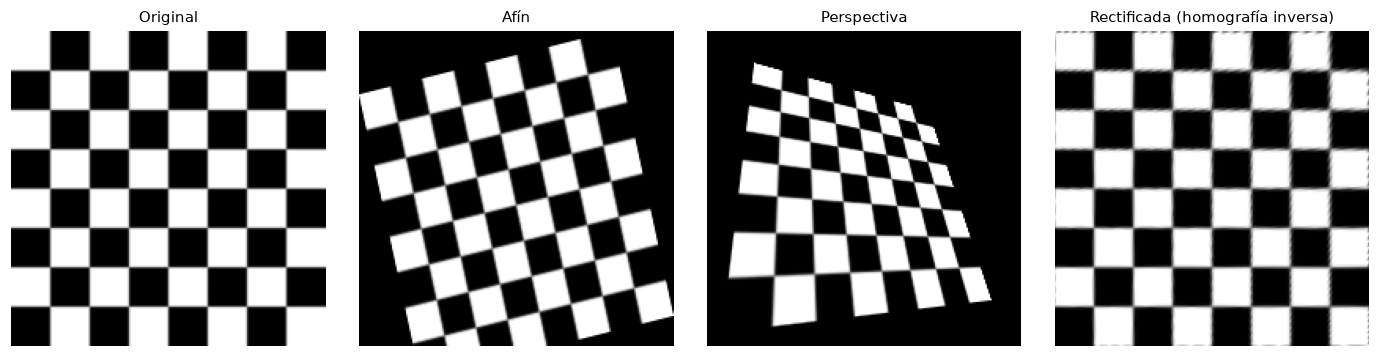

In [13]:
tablero = data.checkerboard()
h, w = tablero.shape
src = np.float32([[0, 0], [w - 1, 0], [w - 1, h - 1], [0, h - 1]])
dst = np.float32([[30, 20], [w - 60, 50], [w - 20, h - 30], [10, h - 10]])
H = cv2.getPerspectiveTransform(src, dst)
inclinada = cv2.warpPerspective(tablero, H, (w, h))
# "Rectificamos" con la homografía inversa: lo que haríamos con un documento fotografiado
H_inv = cv2.getPerspectiveTransform(dst, src)
rectificada = cv2.warpPerspective(inclinada, H_inv, (w, h))
M_af = cv2.getAffineTransform(src[:3], np.float32([[0, 40], [w - 40, 0], [w - 1, h - 20]]))
mostrar([tablero, cv2.warpAffine(tablero, M_af, (w, h)), inclinada, rectificada],
        ["Original", "Afín", "Perspectiva", "Rectificada (homografía inversa)"])

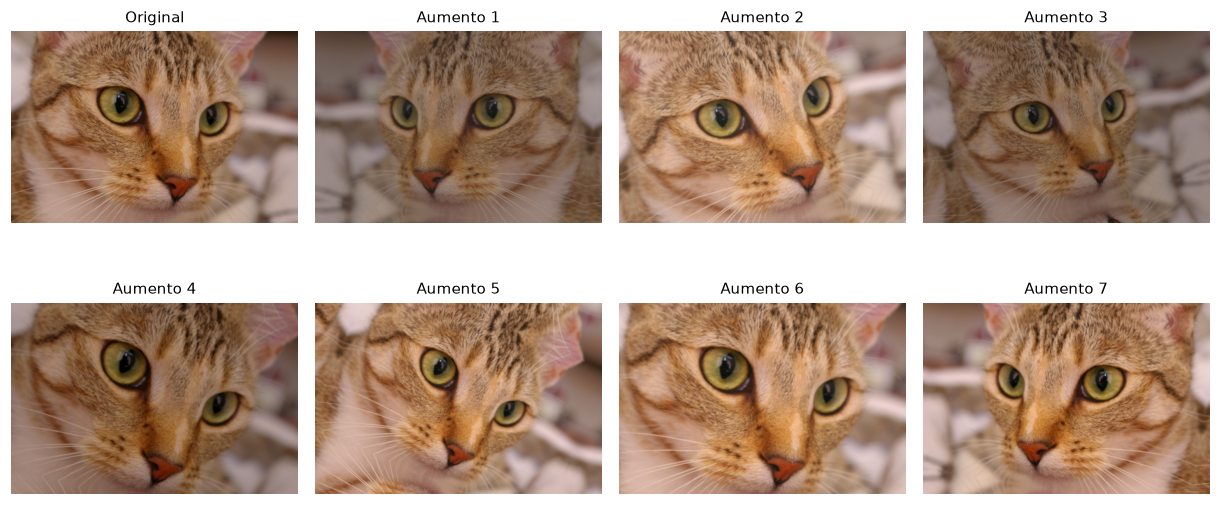

In [14]:
rgb = data.chelsea()
rng = np.random.default_rng(0)

def aumentar(im, rng):
    h, w = im.shape[:2]
    M = cv2.getRotationMatrix2D((w / 2, h / 2), rng.uniform(-25, 25), rng.uniform(0.85, 1.15))
    out = cv2.warpAffine(im, M, (w, h), borderMode=cv2.BORDER_REFLECT)
    if rng.random() < 0.5:
        out = cv2.flip(out, 1)
    out = cv2.convertScaleAbs(out, alpha=rng.uniform(0.7, 1.3), beta=rng.uniform(-30, 30))
    return out

mostrar([rgb] + [aumentar(rgb, rng) for _ in range(7)], ["Original"] + [f"Aumento {i}" for i in range(1, 8)], tam=2.8)

## 8. De técnicas sueltas a un esquema de preprocesamiento
En la actividad 2A integrarás tus decisiones en una función. Un ejemplo:

SSIM entrada: 0.356  →  SSIM tras mediana: 0.864


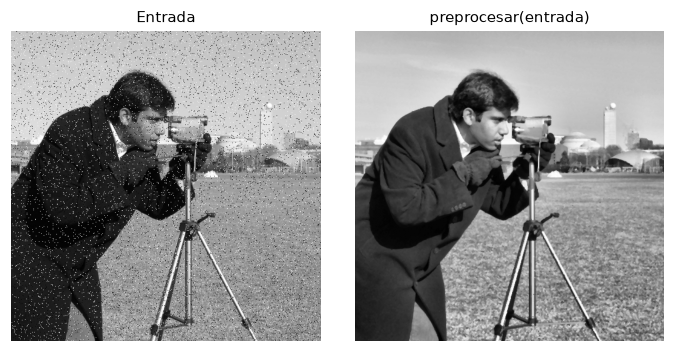

In [15]:
def preprocesar(imagen_gris, kernel_mediana=3, clip=2.0):
    """Esquema propuesto: mediana (ruido impulsivo) → CLAHE (contraste local) → normalización a [0, 1]."""
    x = cv2.medianBlur(imagen_gris, kernel_mediana)
    x = cv2.createCLAHE(clipLimit=clip, tileGridSize=(8, 8)).apply(x)
    return x.astype(np.float32) / 255.0

entrada = ruidos["Sal y pimienta 5%"]
salida = preprocesar(entrada)
print(f"SSIM entrada: {ssim(img, entrada):.3f}  →  SSIM tras mediana: {ssim(img, cv2.medianBlur(entrada, 3)):.3f}")
mostrar([entrada, salida], ["Entrada", "preprocesar(entrada)"])

## 9. Resumen y conexión con la actividad 2A
- Las transformaciones de intensidad e histograma ajustan el contraste; **CLAHE** suele ser la opción más segura.
- La convolución es la base de los filtros… y de las redes convolucionales de la Unidad 5.
- **No elijas un filtro "a ojo":** compara con PSNR/SSIM frente a una referencia.
- Fourier resuelve problemas que el dominio espacial no puede (ruido periódico).
- Morfología limpia máscaras; top-hat corrige iluminación.

**Actividad 2A. Preprocesamiento de imágenes con OpenCV** (15 puntos, entrega: domingo 14 de febrero de 2027). Usa la plantilla `2A_Plantilla_Preprocesamiento.ipynb` y justifica tus decisiones con PSNR y SSIM.